# Where should we measure? A data-worth tutorial

This notebook asks a simple question: **which new measurement would reduce the uncertainty of a prediction the most?**

We use a small synthetic aquifer (500 m × 500 m, heads fixed at 10 m on the west and 5 m on the east) and one prediction: the **outflow** through the east boundary. Conductivity (K) is unknown, so we describe it with 200 random fields that all share the same geostatistics. Running MODFLOW 6 on each gives 200 outflows: their spread is our **prior uncertainty**.

Then, without collecting any data, we estimate how much a measurement *would* help, with the linear data-worth formula:

**Var(after) = Var(before) − Cov(prediction, data) · [Cov(data, data) + error]⁻¹ · Cov(data, prediction)**

## 1. Build the prior ensemble (about 10 s)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import dataworth as dw

MF6 = "mf6"          # full path to the MODFLOW 6 executable if it is not on your PATH
lnk, heads, outflow = dw.make_ensemble(mf6_exe=MF6)
print(f"{len(outflow)} members; outflow {outflow.mean():.0f} ± {outflow.std(ddof=1):.0f} m3/d")

200 members; outflow 433 ± 119 m3/d


## 2. What does one measurement do?
We compare one K measurement and one head at the same place, in the centre.

In [2]:
for label, k, h in [("nothing", [], []), ("1 K at the centre", [(25, 25)], []), ("1 head at the centre", [], [(25, 25)])]:
    before, after, _ = dw.worth(lnk, heads, outflow, k, h)
    print(f"{label:22s} outflow uncertainty {before:5.1f} -> {after:5.1f} m3/d")

nothing                outflow uncertainty 118.9 -> 118.9 m3/d
1 K at the centre      outflow uncertainty 118.9 -> 112.1 m3/d
1 head at the centre   outflow uncertainty 118.9 -> 118.2 m3/d


## 3. More data: K versus heads
The same 36 locations, measured either as K or as heads.

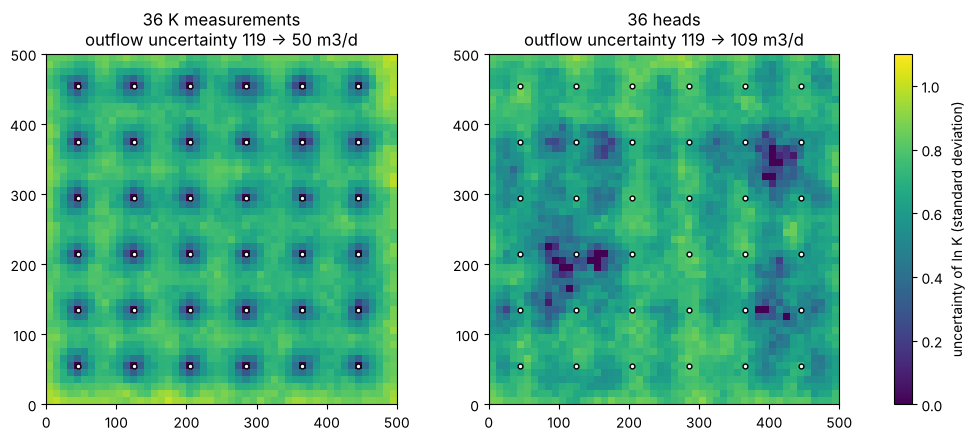

In [3]:
grid = [(r, c) for r in range(4, 50, 8) for c in range(4, 50, 8)]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.3), constrained_layout=True)
for a, (label, k, h) in zip(ax, [("36 K measurements", grid, []), ("36 heads", [], grid)]):
    before, after, sd_map = dw.worth(lnk, heads, outflow, k, h)
    im = a.imshow(sd_map, vmin=0, vmax=1.1, extent=[0, 500, 0, 500])
    a.scatter([c * 10 + 5 for r, c in grid], [500 - r * 10 - 5 for r, c in grid], s=12, c="w", edgecolor="k")
    a.set_title(f"{label}\noutflow uncertainty {before:.0f} -> {after:.0f} m3/d")
fig.colorbar(im, ax=ax, label="uncertainty of ln K (standard deviation)"); plt.show()

**What to notice:** both reduce the uncertainty of the conductivity *field*, but only K measurements strongly reduce the uncertainty of the *outflow*.
With heads fixed at the boundaries, multiplying K everywhere by the same factor does not change the heads, so heads cannot tell how permeable the aquifer is overall, and that is exactly what controls the outflow.

## 4. Where would the next measurement help most?
For every candidate cell, the share of the outflow variance that one more measurement would remove.

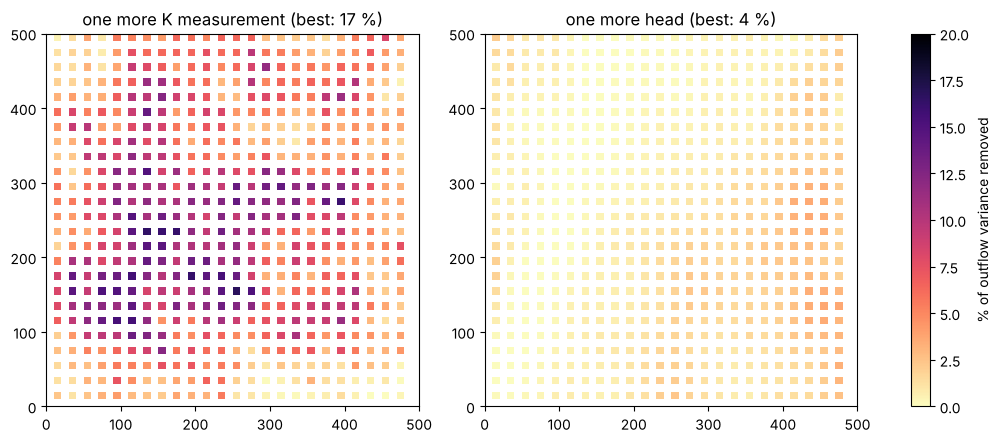

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.3), constrained_layout=True)
for a, kind in zip(ax, ["K", "H"]):
    g = dw.best_next(lnk, heads, outflow, kind=kind)
    im = a.imshow(100 * g, vmin=0, vmax=20, cmap="magma_r", extent=[0, 500, 0, 500])
    a.set_title(f"one more {'K measurement' if kind == 'K' else 'head'} (best: {100 * np.nanmax(g):.0f} %)")
fig.colorbar(im, ax=ax, label="% of outflow variance removed"); plt.show()

## 5. A simple monitoring design: add the best location, five times

In [5]:
k_cells, sd_path = [], []
for step in range(5):
    g = dw.best_next(lnk, heads, outflow, k_cells, [], kind="K")
    r, c = np.unravel_index(np.nanargmax(g), g.shape)
    k_cells.append((int(r), int(c)))
    sd_path.append(dw.worth(lnk, heads, outflow, k_cells, [])[1])
    print(f"step {step + 1}: K at row {r}, column {c} -> outflow uncertainty {sd_path[-1]:.0f} m3/d")

step 1: K at row 34, column 25 -> outflow uncertainty 108 m3/d


step 2: K at row 34, column 3 -> outflow uncertainty 99 m3/d


step 3: K at row 18, column 13 -> outflow uncertainty 90 m3/d


step 4: K at row 8, column 39 -> outflow uncertainty 85 m3/d


step 5: K at row 40, column 39 -> outflow uncertainty 79 m3/d


**What to notice:** the first measurements help most; later ones help less, partly because they overlap with what is already known (redundancy).

## Try it yourself
- Change the prediction: e.g. the head at one cell instead of the outflow (edit `worth` to use `heads` as the prediction).
- Change the boundary condition to a specified flux and see whether heads become useful.
- Change the measurement errors `dw.SIGMA_H` and `dw.SIGMA_LNK`.

**Limits:** the formula is linear; it is exact for K measurements here and approximate for heads. It also tells you how much the *reported* uncertainty would shrink, not whether the prediction becomes *correct*, which depends on the model and the prior being adequate.